In [ ]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import Lasso , Ridge, ElasticNet
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score , StratifiedKFold , GridSearchCV , RandomizedSearchCV

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import AdaBoostRegressor, BaggingRegressor, GradientBoostingRegressor
from sklearn.ensemble import  VotingRegressor, StackingRegressor
from xgboost import XGBRegressor

from sklearn.metrics import mean_squared_error, r2_score ,  mean_absolute_error


In [2]:
df = pd.read_csv("data.csv", encoding="latin-1")
df.head()

C:\Users\MS\AppData\Local\Temp\ipykernel_23924\505440291.py:1: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data.csv", encoding="latin-1")


,stn_code,sampling_date,state,location,agency,type,so2,no2,rspm,spm,location_monitoring_station,pm2_5,date
0,150.0,February - M021990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",4.8,17.4,NaN,NaN,NaN,NaN,1990-02-01
1,151.0,February - M021990,Andhra Pradesh,Hyderabad,NaN,Industrial Area,3.1,7.0,NaN,NaN,NaN,NaN,1990-02-01
2,152.0,February - M021990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",6.2,28.5,NaN,NaN,NaN,NaN,1990-02-01
3,150.0,March - M031990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",6.3,14.7,NaN,NaN,NaN,NaN,1990-03-01
4,151.0,March - M031990,Andhra Pradesh,Hyderabad,NaN,Industrial Area,4.7,7.5,NaN,NaN,NaN,NaN,1990-03-01


In [3]:
df.drop(columns = ["pm2_5", "sampling_date", "stn_code" , "spm"], axis = 1 , inplace = True)

In [4]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df.dropna(subset=["date"], inplace=True)
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df.drop(columns="date", inplace=True)

In [5]:
df["type"] = df["type"].replace({
    "Industrial Areas": "Industrial", "Industrial Area": "Industrial",
    "Residential, Rural and other Areas": "Residential",
    "Residential and others": "Residential", "RIRUO": "Residential",
    "Sensitive Areas": "Sensitive", "Sensitive Area": "Sensitive"})

In [6]:
df.head()

,state,location,agency,type,so2,no2,rspm,location_monitoring_station,year,month
0,Andhra Pradesh,Hyderabad,NaN,Residential,4.8,17.4,NaN,NaN,1990,2
1,Andhra Pradesh,Hyderabad,NaN,Industrial,3.1,7.0,NaN,NaN,1990,2
2,Andhra Pradesh,Hyderabad,NaN,Residential,6.2,28.5,NaN,NaN,1990,2
3,Andhra Pradesh,Hyderabad,NaN,Residential,6.3,14.7,NaN,NaN,1990,3
4,Andhra Pradesh,Hyderabad,NaN,Industrial,4.7,7.5,NaN,NaN,1990,3


In [7]:
df.duplicated().sum()

np.int64(8914)

In [8]:
df.drop_duplicates(inplace = True)
df.reset_index(drop = True , inplace = True)
df.duplicated().sum()

np.int64(0)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426821 entries, 0 to 426820
Data columns (total 10 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   state                        426821 non-null  object 
 1   location                     426821 non-null  object 
 2   agency                       278874 non-null  object 
 3   type                         421709 non-null  object 
 4   so2                          394475 non-null  float64
 5   no2                          412805 non-null  float64
 6   rspm                         389342 non-null  float64
 7   location_monitoring_station  400513 non-null  object 
 8   year                         426821 non-null  int32  
 9   month                        426821 non-null  int32  
dtypes: float64(3), int32(2), object(5)
memory usage: 29.3+ MB


In [10]:
df = df[df["rspm"] <= df["rspm"].quantile(0.99)].reset_index(drop=True)

In [11]:
df.shape

(385448, 10)

# EDA #

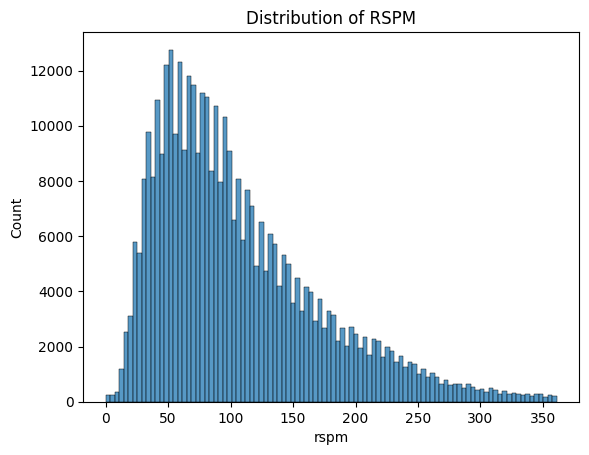

In [12]:
sns.histplot(df["rspm"], bins=100)
plt.title("Distribution of RSPM")
plt.show()

# BoxPlot To Know Outliers #

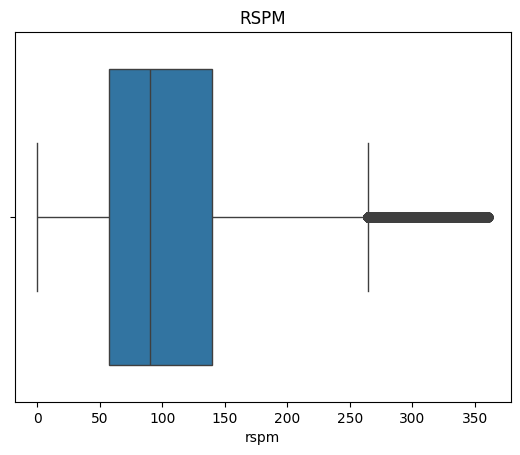

In [13]:
sns.boxplot(x=df["rspm"])
plt.title("RSPM")
plt.show()

# High state Have Pollution #

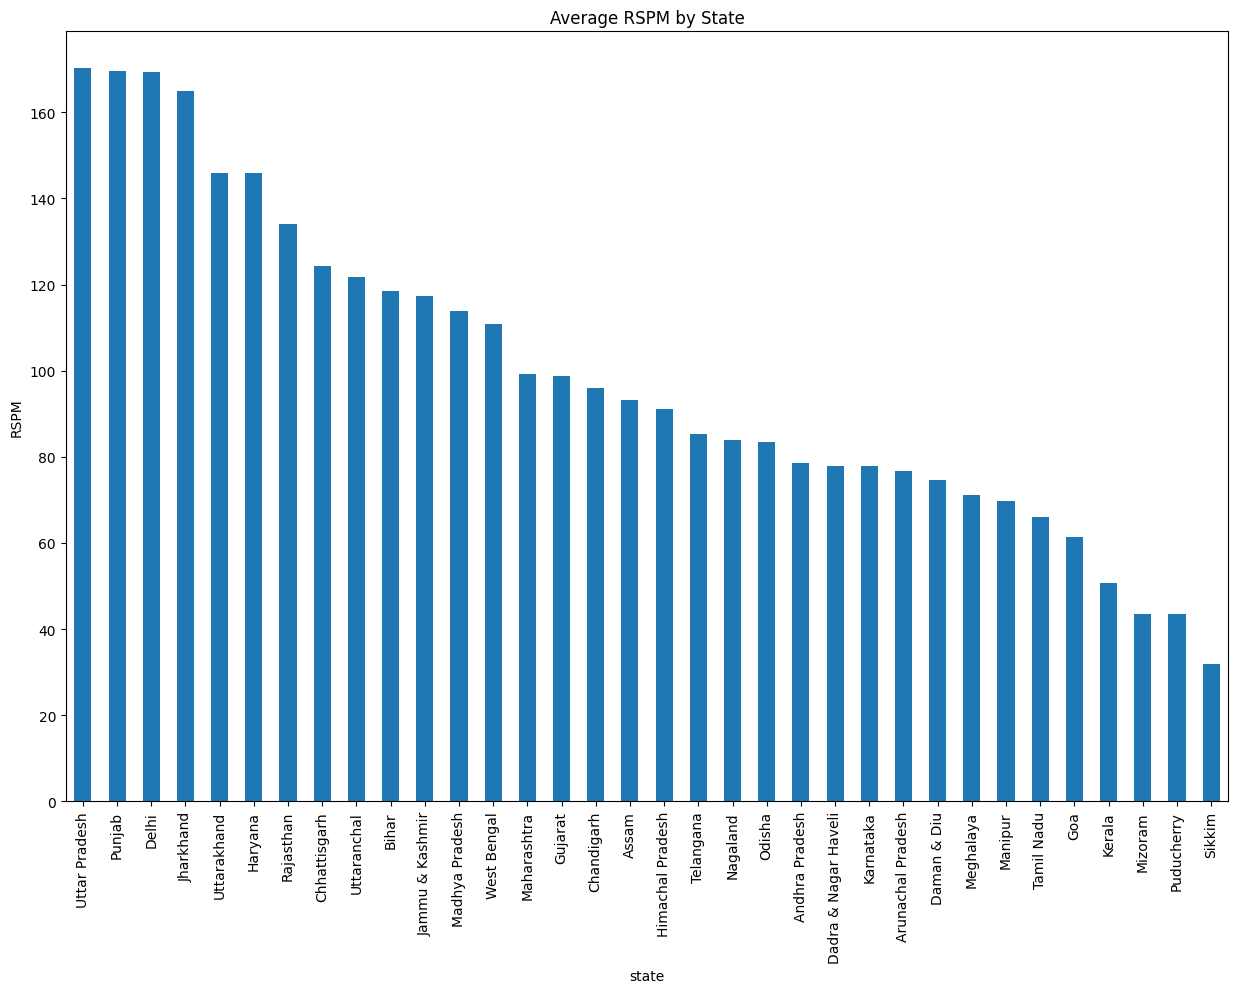

In [14]:
plt.figure(figsize=(15, 10))
df.groupby("state")["rspm"].mean().sort_values(ascending=False).plot(kind="bar")
plt.title("Average RSPM by State")
plt.ylabel("RSPM")
plt.show()

# Month And Year that increase Pollution in it #

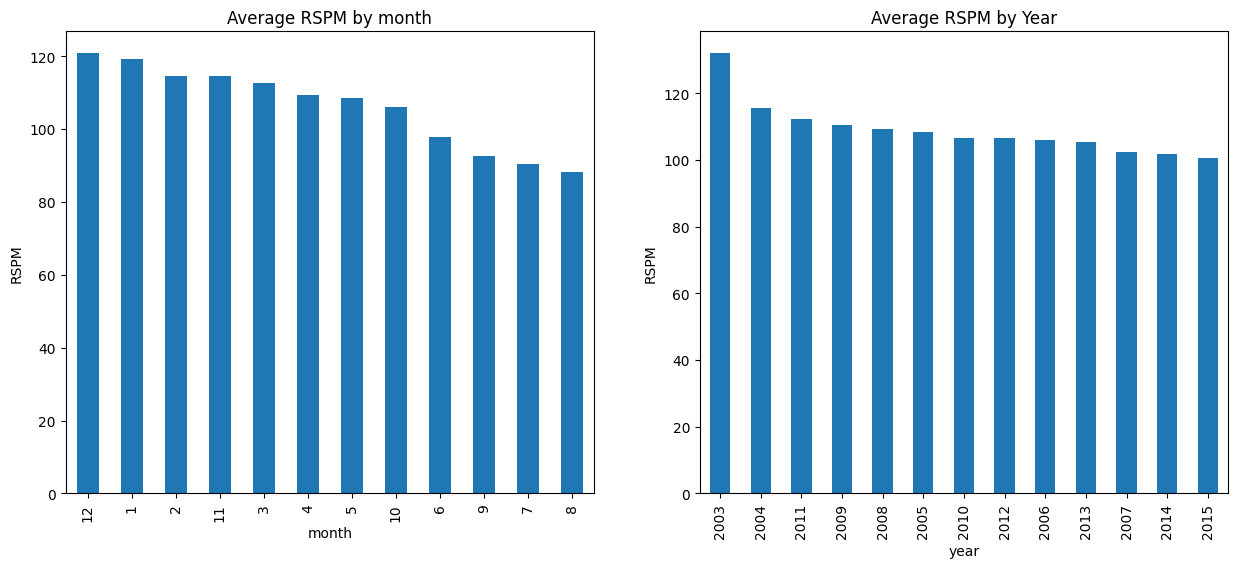

In [15]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
df.groupby("month")["rspm"].mean().sort_values(ascending=False).plot(kind="bar")
plt.title("Average RSPM by month")
plt.ylabel("RSPM")

plt.subplot(1,2,2)

df.groupby("year")["rspm"].mean().sort_values(ascending=False).plot(kind="bar")
plt.title("Average RSPM by Year")
plt.ylabel("RSPM")

plt.show()

# Relationship Between SO2 , NO2 and RSPM #

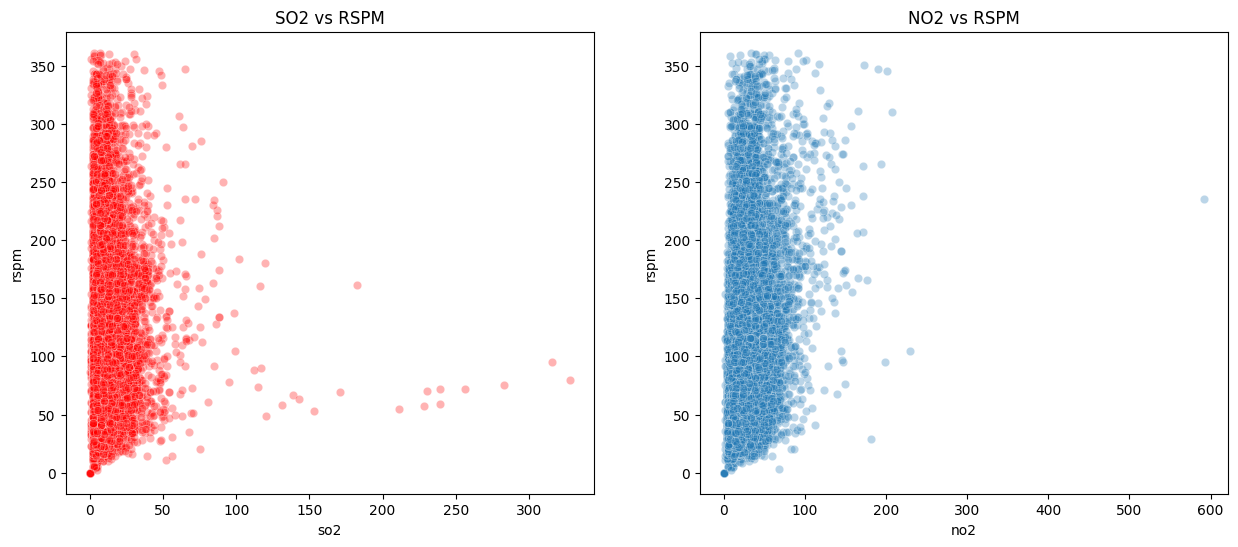

In [16]:
plt.figure(figsize=(15, 6))

# First Subplot
plt.subplot(1, 2, 1)
sample = df.sample(20000, random_state=42)
sns.scatterplot(data=sample, x="so2", y="rspm", alpha=0.3 , color = "r")
plt.title("SO2 vs RSPM")

# Second Subplot
plt.subplot(1, 2, 2)
sns.scatterplot(data=sample, x="no2", y="rspm", alpha=0.3)
plt.title("NO2 vs RSPM")

plt.show()

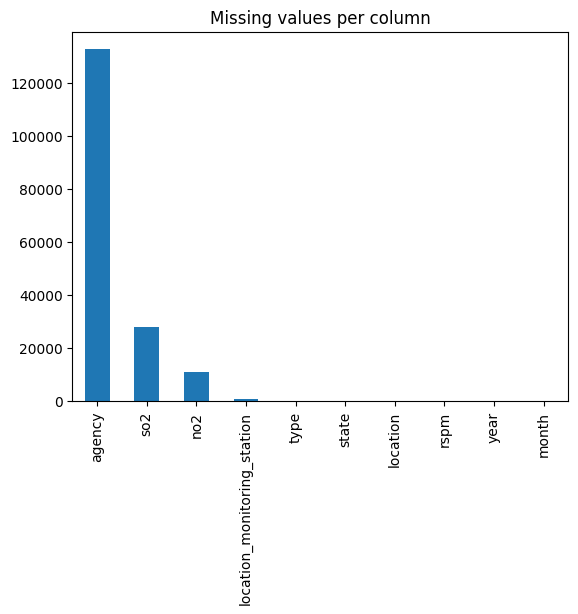

In [17]:

df.isna().sum().sort_values(ascending=False).plot(kind="bar")
plt.title("Missing values per column")
plt.show()

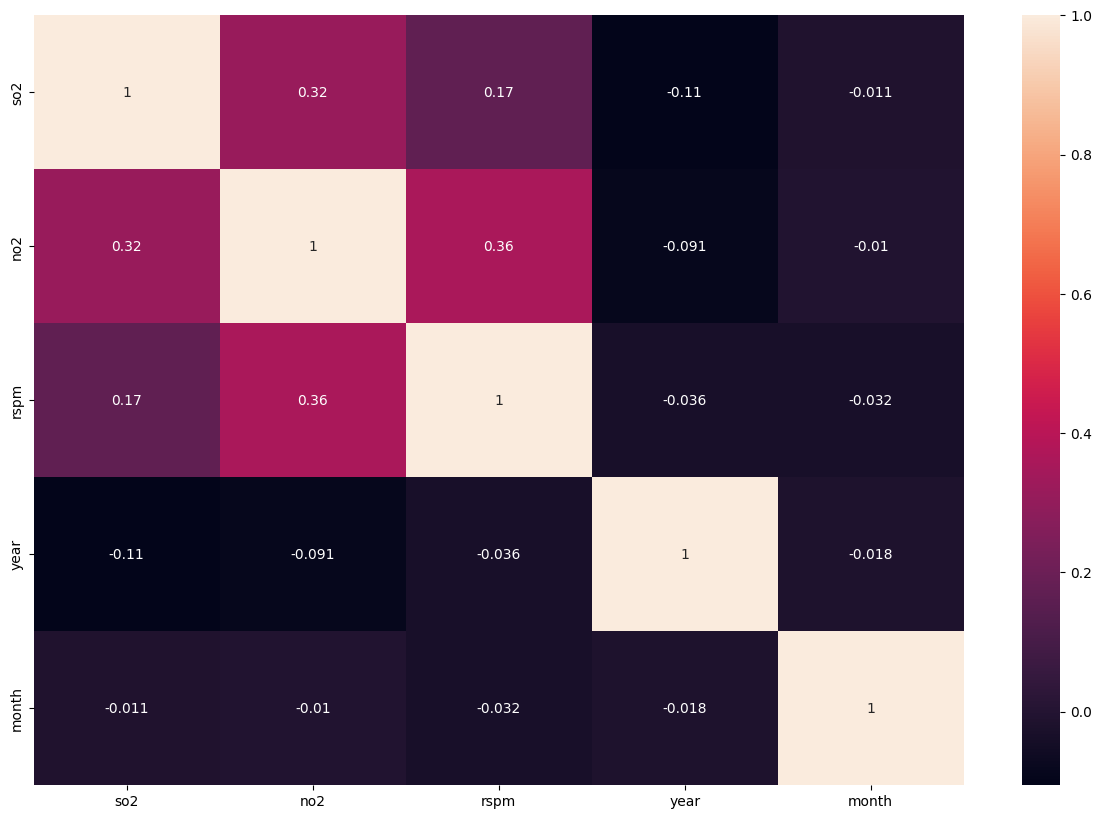

In [18]:
plt.figure(figsize = (15,10))
sns.heatmap(df.corr(numeric_only = True) , annot = True)
plt.show()

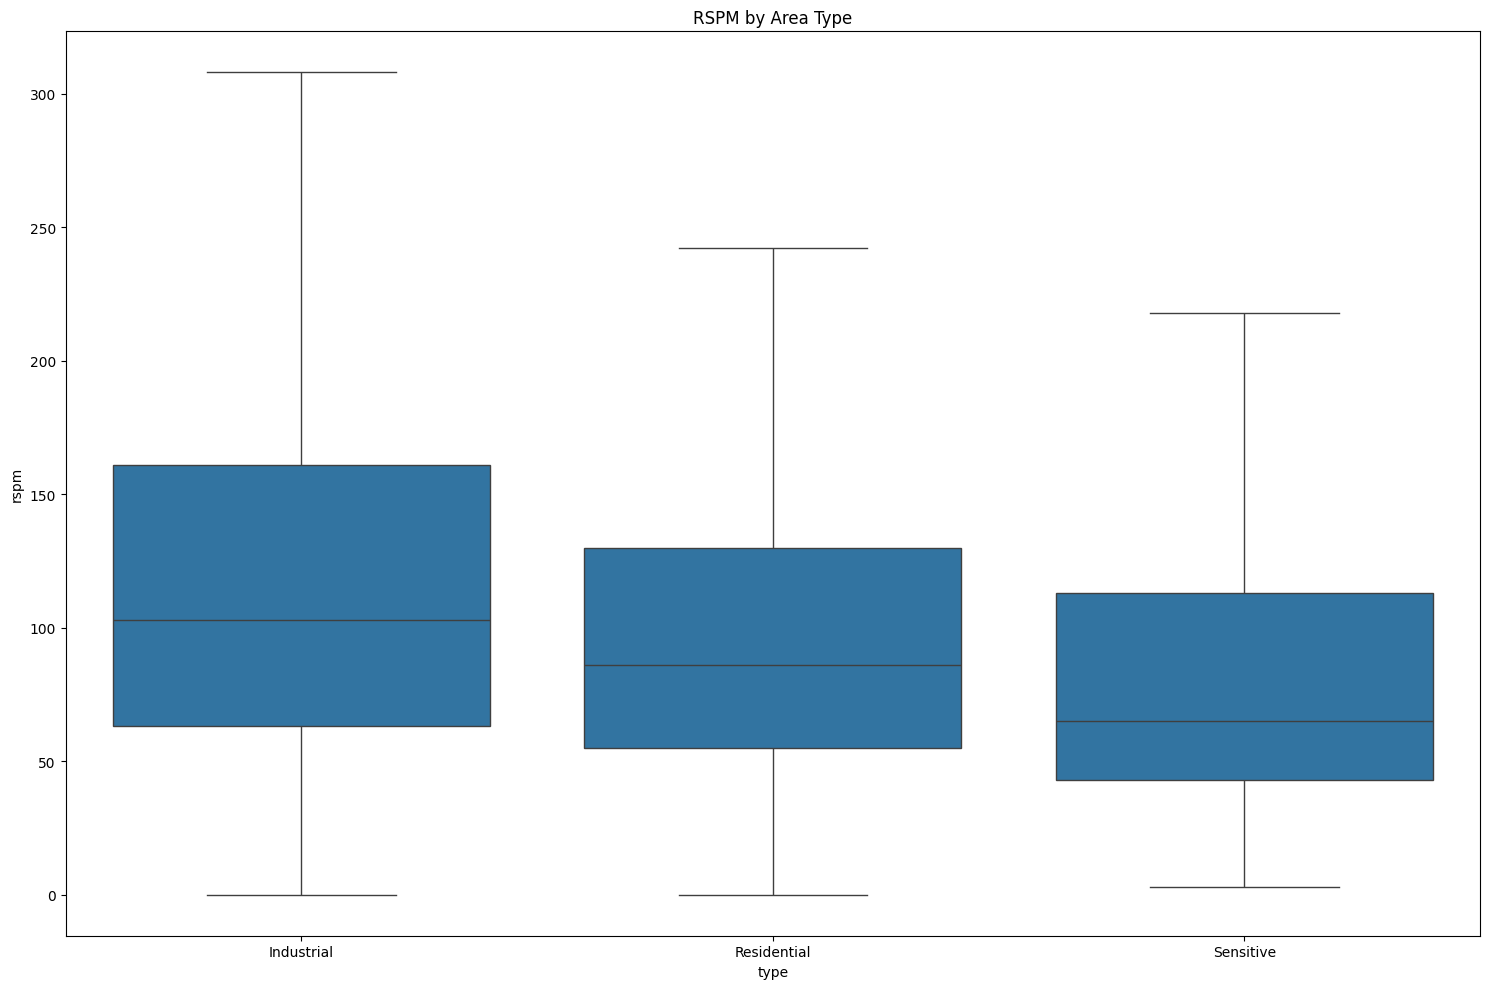

In [19]:
plt.figure(figsize=(15,10))

sns.boxplot(data=df, x="type", y="rspm", showfliers=False)
plt.title("RSPM by Area Type")
plt.tight_layout()
plt.show()



In [20]:
df.dropna(subset= "rspm", inplace = True)
df.reset_index(drop = True , inplace = True)
df["rspm"].isna().sum()

np.int64(0)

In [21]:
X = df.drop("rspm" , axis = 1)
y = df["rspm"]

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

Numeric: ['so2', 'no2', 'year', 'month']
Categorical: ['state', 'location', 'agency', 'type', 'location_monitoring_station']


In [24]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
])

In [25]:
preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])
preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


In [26]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge":             Ridge(),
    "Lasso":             Lasso(),
    "ElasticNet":        ElasticNet(),
    "Decision Tree":     DecisionTreeRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost":           XGBRegressor(n_estimators=300, learning_rate=0.1, n_jobs=-1, random_state=42)
}

In [ ]:
results = []

for name, model_obj in models.items():
    print(f"=== {name} ===")
    pipeline = Pipeline([
        ("prep", preprocessor),
        ("model", model_obj)
    ])
    
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    r2 = r2_score(y_test, pred)
    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)

    results.append({
        "Model": name,
        "R2": r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse
    })

    print("R2 :", r2)
    print("MAE:", mae)
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("-" * 30)

# Convert results to DataFrame
results_df = pd.DataFrame(results)

results_df

=== Linear Regression ===
R2 : 0.15721764217317036
MAE: 46.14349183221663
MSE: 3640.7782021805706
RMSE: 60.33886145910089
------------------------------
=== Ridge ===
R2 : 0.1572176644653711
MAE: 46.143496033992484
MSE: 3640.7781058793635
RMSE: 60.3388606610977
------------------------------
=== Lasso ===
R2 : 0.15628630929549592
MAE: 46.275212921553724
MSE: 3644.8015142593313
RMSE: 60.37219156415751
------------------------------
=== ElasticNet ===
R2 : 0.14580277608460457
MAE: 46.90845583646785
MSE: 3690.0898604635267
RMSE: 60.746109838108374
------------------------------
=== Decision Tree ===
R2 : 0.45171795116547975
MAE: 30.641177629127437
MSE: 2368.551398241048
RMSE: 48.6677654946377
------------------------------
=== Gradient Boosting ===
R2 : 0.4630483837685787
MAE: 35.37808403751421
MSE: 2319.6044884492853
RMSE: 48.16227245935646
------------------------------
=== XGBoost ===
R2 : 0.6584757374751204
MAE: 26.520815683220253
MSE: 1475.3679629965231
RMSE: 38.41051891079478
------

,Model,R2,MAE,MSE,RMSE
0,Linear Regression,0.157218,46.143492,3640.778202,60.338861
1,Ridge,0.157218,46.143496,3640.778106,60.338861
2,Lasso,0.156286,46.275213,3644.801514,60.372192
3,ElasticNet,0.145803,46.908456,3690.089860,60.746110
4,Decision Tree,0.451718,30.641178,2368.551398,48.667765
5,Gradient Boosting,0.463048,35.378084,2319.604488,48.162272
6,XGBoost,0.658476,26.520816,1475.367963,38.410519


In [28]:
print(y.name)
print(y_train.describe())
print(y_test.describe())
print(X_train.shape, X_test.shape)

rspm
count    308358.000000
mean        106.299073
std          66.038366
min           0.000000
25%          56.330000
50%          90.000000
75%         141.000000
max         361.000000
Name: rspm, dtype: float64
count    77090.000000
mean       105.894573
std         65.726758
min          0.000000
25%         57.000000
50%         90.000000
75%        140.000000
max        361.000000
Name: rspm, dtype: float64
(308358, 9) (77090, 9)


In [36]:
params = {
    "model__n_estimators": [500, 1000],
    "model__max_depth": [8, 10],
    "model__learning_rate": [0.05, 0.1],
    "model__min_child_weight": [1,  5],
}

pipeline = Pipeline([
        ("prep", preprocessor),
        ("model",  XGBRegressor(subsamle = .8, 
                                colsample_bytree = .8 , 
                                tree_method ="hist" , n_jobs=-1, random_state=42))
    ])

X_gs = X_train.sample(100000, random_state=42)
y_gs = y_train.loc[X_gs.index]


grid = GridSearchCV(
    estimator=pipeline,
    param_grid=params,
    cv=5,
    scoring="r2",
    n_jobs=1,
    verbose = 2
)

grid.fit(X_gs, y_gs)

print("Best Parameters:", grid.best_params_)
print("Best Score:", grid.best_score_)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


c:\Users\MS\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:16:03] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "subsamle" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[CV] END model__learning_rate=0.05, model__max_depth=8, model__min_child_weight=1, model__n_estimators=500; total time=   3.8s


c:\Users\MS\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:16:07] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "subsamle" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[CV] END model__learning_rate=0.05, model__max_depth=8, model__min_child_weight=1, model__n_estimators=500; total time=   3.7s


c:\Users\MS\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:16:11] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "subsamle" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


... (153 outputs left out)

c:\Users\MS\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:27:38] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "subsamle" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[CV] END model__learning_rate=0.1, model__max_depth=10, model__min_child_weight=5, model__n_estimators=1000; total time=  13.2s


c:\Users\MS\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:27:52] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "subsamle" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best Parameters: {'model__learning_rate': 0.05, 'model__max_depth': 10, 'model__min_child_weight': 5, 'model__n_estimators': 500}
Best Score: 0.6741533278391714


In [37]:
best_model = grid.best_estimator_
best_model.fit(X_train , y_train)

c:\Users\MS\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:28:27] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "subsamle" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,steps,"[('prep', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [38]:
y_pred = best_model.predict(X_test)

In [39]:
print("R2:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2: 0.7112033904010561
MAE: 23.47080717355326
RMSE: 35.32119907344294


In [ ]:
import joblib, json

joblib.dump(best_model, "rspm_model.pkl")


meta = {"states": {}, "types": sorted(X_train["type"].dropna().unique().tolist()),
        "metrics": {"R2": float(r2_score(y_test, y_pred)),
                    "MAE": float(mean_absolute_error(y_test, y_pred)),
                    "RMSE": float(np.sqrt(mean_squared_error(y_test, y_pred)))},
        "so2_median": float(X_train["so2"].median()), "no2_median": float(X_train["no2"].median())}

mode = lambda s: s.mode().iloc[0] if s.notna().any() else None
for (state, loc), g in X_train.groupby(["state", "location"]):
    meta["states"].setdefault(state, {})[loc] = {
        "agency": mode(g["agency"]),
        "station": mode(g["location_monitoring_station"]),
        "type": mode(g["type"]),
    }
with open("app_metadata.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=1)
print("Saved rspm_model.pkl + app_metadata.json")

Saved rspm_model.pkl + app_metadata.json


In [42]:
import json
from datetime import date

import joblib
import pandas as pd
import streamlit as st

st.set_page_config(page_title="India Air Quality – RSPM Predictor", page_icon="🌫️", layout="centered")


@st.cache_resource
def load_model():
    return joblib.load("rspm_model.pkl")          # Pipeline = preprocessing + XGBoost


@st.cache_data
def load_meta():
    with open("app_metadata.json", encoding="utf-8") as f:
        return json.load(f)


model, meta = load_model(), load_meta()


def aqi_category(v):
    # تصنيف PM10 حسب الـ National AQI الهندي (24 ساعة)
    for limit, label, color in [(50, "Good", "#2e7d32"), (100, "Satisfactory", "#7cb342"),
                                (250, "Moderate", "#f9a825"), (350, "Poor", "#ef6c00"),
                                (430, "Very Poor", "#c62828")]:
        if v <= limit:
            return label, color
    return "Severe", "#6a1b9a"


st.title("🌫️ RSPM (PM10) Predictor")
st.caption("Predicts Respirable Suspended Particulate Matter (µg/m³) for Indian monitoring stations "
           "using a tuned XGBoost pipeline trained on CPCB data (1987–2015).")

with st.sidebar:
    st.header("Model performance (test set)")
    m = meta["metrics"]
    st.metric("R²", f"{m['R2']:.3f}")
    st.metric("MAE", f"{m['MAE']:.1f} µg/m³")
    st.metric("RMSE", f"{m['RMSE']:.1f} µg/m³")

st.subheader("Location")
c1, c2 = st.columns(2)
state = c1.selectbox("State", sorted(meta["states"]))
location = c2.selectbox("City / Location", sorted(meta["states"][state]))
info = meta["states"][state][location]

types = meta["types"]
area = st.selectbox("Area type", types, index=types.index(info["type"]) if info["type"] in types else 0)

st.subheader("Measurements")
c3, c4, c5 = st.columns(3)
so2 = c3.number_input("SO₂ (µg/m³)", min_value=0.0, max_value=1000.0, value=round(meta["so2_median"], 1))
no2 = c4.number_input("NO₂ (µg/m³)", min_value=0.0, max_value=1000.0, value=round(meta["no2_median"], 1))
d = c5.date_input("Date", value=date(2015, 1, 15), min_value=date(1987, 1, 1), max_value=date(2030, 12, 31))

with st.expander("Station details (filled automatically from the selected city)"):
    st.write(f"**Agency:** {info['agency'] or '—'}")
    st.write(f"**Monitoring station:** {info['station'] or '—'}")

if st.button("Predict RSPM", type="primary", use_container_width=True):
    row = pd.DataFrame([{
        "state": state, "location": location, "agency": info["agency"], "type": area,
        "so2": so2, "no2": no2, "location_monitoring_station": info["station"],
        "year": d.year, "month": d.month,
    }])
    pred = max(float(model.predict(row)[0]), 0.0)
    label, color = aqi_category(pred)
    st.markdown(
        f"<div style='padding:1.2rem;border-radius:12px;background:{color}22;border-left:6px solid {color}'>"
        f"<div style='font-size:0.95rem;opacity:.8'>Predicted RSPM</div>"
        f"<div style='font-size:2.4rem;font-weight:700'>{pred:.1f} µg/m³</div>"
        f"<div style='font-size:1.1rem;color:{color};font-weight:600'>{label}</div></div>",
        unsafe_allow_html=True)
    if d.year > 2015:
        st.info("The model was trained on data up to 2015 — predictions for later years are extrapolations.")

2026-11-20 04:31:27.615 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-20 04:31:27.618 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-20 04:31:27.619 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-20 04:31:27.688 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-20 04:31:27.690 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-20 04:31:27.714 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in